<a href="https://colab.research.google.com/github/gguex/ISH_ressources_cours_ML/blob/main/TP05c_corrige.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 5 : Corrigé de l'exercice

Adaptation du code du TP aux fichiers `usarrests.csv` et `states_meta.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
# Pour standardiser
from sklearn.preprocessing import StandardScaler
# Les deux méthodes de clustering
from sklearn.cluster import KMeans, AgglomerativeClustering
# Les mesures : silhouette, information mutuelle ajustée, rapport F
from sklearn.metrics import silhouette_score, adjusted_mutual_info_score
from sklearn.feature_selection import f_classif
# Pour dessiner un dendrogramme et faire un test du chi2
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import chi2_contingency

# Le même style de graphiques qu'aux TP précédents
sns.set_theme(style="whitegrid", palette="colorblind")

In [2]:
# Connexion à Google Drive sur Colab ; dossier local sinon
try:
    from google.colab import drive
except ImportError:
    data_path = Path("data") / "TP5"
else:
    drive.mount("/content/drive")
    data_path = Path("/content/drive/MyDrive/Colab Notebooks/data/TP5")

Mounted at /content/drive


**1.** Chargement, jointure sur `Name`, noms des États en index. **2.** Standardisation des quatre variables de criminalité :

In [3]:
arrests = pd.read_csv(data_path / "usarrests.csv")
states_meta = pd.read_csv(data_path / "states_meta.csv")
data = pd.merge(arrests, states_meta, on="Name").set_index("Name")

crime_variables = ["Murder", "Assault", "UrbanPop", "Rape"]
political_variables = ["abortion", "environment", "gay_rights", "families_payments"]

scaler = StandardScaler()
inputs_std = pd.DataFrame(scaler.fit_transform(data[crime_variables]),
                          columns=crime_variables, index=data.index)
data.head()

,Murder,Assault,UrbanPop,Rape,region,abortion,environment,gay_rights,families_payments
Name,,,,,,,,,
Alabama,13.2,236,58,21.2,south,1,10,0.000,407.969884
Alaska,10.0,263,48,44.5,west,12,9,0.125,853.059666
Arizona,8.1,294,80,31.0,plains,3,13,0.250,617.634499
Arkansas,8.8,190,50,19.5,south,1,9,0.000,602.062891
California,9.0,276,91,40.6,west,13,38,0.875,1107.064561


**3.** Inertie et silhouette pour $k$ de 2 à 8 :

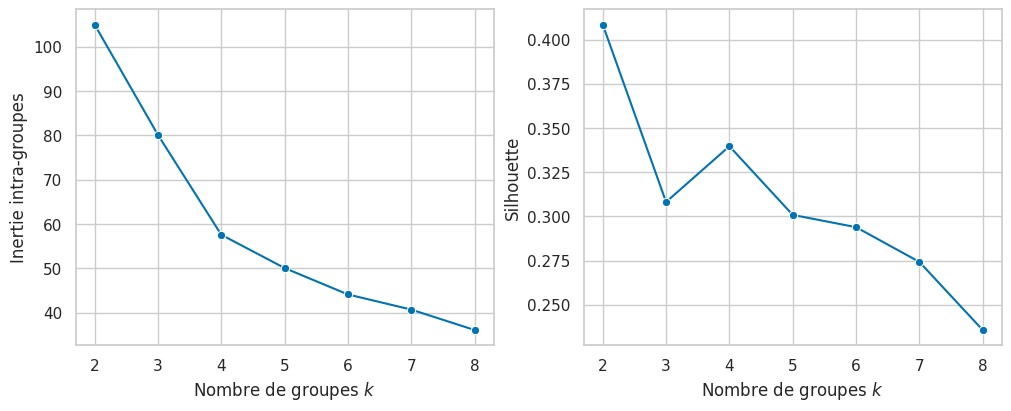

,Inertie intra-groupes,Silhouette
2,104.962,0.408
3,80.086,0.308
4,57.554,0.340
5,50.051,0.301
6,44.092,0.294
7,40.676,0.274
8,36.074,0.236


In [4]:
k_values = range(2, 9)
inertias, silhouettes = [], []
for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(inputs_std)
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(inputs_std, kmeans.labels_))
kmeans_scores = pd.DataFrame({"Inertie intra-groupes": inertias, "Silhouette": silhouettes}, index=k_values)

fig, axs = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
sns.lineplot(x=kmeans_scores.index, y=kmeans_scores["Inertie intra-groupes"], marker="o", ax=axs[0])
sns.lineplot(x=kmeans_scores.index, y=kmeans_scores["Silhouette"], marker="o", ax=axs[1])
axs[0].set(xlabel="Nombre de groupes $k$")
axs[1].set(xlabel="Nombre de groupes $k$")
plt.show()
kmeans_scores.round(3)

La silhouette est maximale à $k = 2$ (forte contre faible criminalité) avec un second sommet à $k = 4$ ; l'inertie n'a pas de coude net. Quatre groupes restent lisibles avec 50 États et décrivent plus finement : on retient $k = 4$, en notant que $k = 2$ est défendable.

**4.** Profils (colonne `Groupe k-means`) et rapport F, pour les variables de criminalité et les scores politiques :

In [5]:
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
kmeans.fit(inputs_std)
data["Groupe k-means"] = kmeans.labels_

profiles = data.groupby("Groupe k-means")[crime_variables].mean()
profiles.insert(0, "Effectif", data["Groupe k-means"].value_counts().sort_index())
profiles.round(1)

,Effectif,Murder,Assault,UrbanPop,Rape
Groupe k-means,,,,,
0,16,5.7,138.9,73.9,18.8
1,8,13.9,243.6,53.8,21.4
2,13,3.6,78.5,52.1,12.2
3,13,10.8,257.4,76.0,33.2


In [6]:
all_variables = crime_variables + political_variables
f_values, p_values = f_classif(data[all_variables], data["Groupe k-means"])
pd.DataFrame({"F": f_values, "p-valeur": p_values}, index=all_variables) \
    .sort_values("F", ascending=False).round({"F": 1})

,F,p-valeur
Assault,55.7,2.376392e-15
Murder,53.5,4.927378e-15
Rape,36.3,3.480110e-12
UrbanPop,21.6,7.138448e-09
families_payments,6.4,1.000328e-03
gay_rights,2.9,4.318793e-02
abortion,2.5,7.159710e-02
environment,1.7,1.819544e-01


Groupe 1 : criminalité élevée, peu urbain (8 États). Groupe 3 : criminalité élevée, très urbain. Groupe 0 : urbain, criminalité modérée. Groupe 2 : rural, faible criminalité. `Assault` et `Murder` discriminent le plus, `UrbanPop` le moins.

Parmi les scores politiques, seul `families_payments` est nettement lié aux groupes (p = 0.001) ; `gay_rights` l'est faiblement, `abortion` et `environment` pas du tout.

**5.** Les trois États les plus typiques de chaque groupe :

In [7]:
distances = pd.DataFrame(kmeans.transform(inputs_std), index=data.index)
data["Distance au centroïde"] = distances.min(axis=1)
data.sort_values("Distance au centroïde").groupby("Groupe k-means").head(3)[["Groupe k-means", "Distance au centroïde"] + crime_variables].round(2)

,Groupe k-means,Distance au centroïde,Murder,Assault,UrbanPop,Rape
Name,,,,,,
Alabama,1,0.36,13.2,236,58,21.2
Michigan,3,0.39,12.1,255,74,35.1
Oklahoma,0,0.50,6.6,151,68,20.0
South Dakota,2,0.51,3.8,86,45,12.8
Ohio,0,0.53,7.3,120,75,21.4
Iowa,2,0.55,2.2,56,57,11.3
New Mexico,3,0.57,11.4,285,70,32.1
New Hampshire,2,0.59,2.1,57,56,9.5
South Carolina,1,0.61,14.4,279,48,22.5


**6.** `Groupe k-means` et `region` :

In [8]:
contingency = pd.crosstab(data["Groupe k-means"], data["region"])
chi2, p_value, degrees, expected = chi2_contingency(contingency)
print(f"Test du chi2 : chi2 = {chi2:.1f}, p-valeur = {p_value:.3f}")
print(f"AMI entre Groupe k-means et region : {adjusted_mutual_info_score(data['region'], data['Groupe k-means']):.2f}")
contingency

Test du chi2 : chi2 = 36.0, p-valeur = 0.002
AMI entre Groupe k-means et region : 0.16


region,midatlantic,midwest,newengland,plains,south,west
Groupe k-means,,,,,,
0,3,2,3,3,2,3
1,0,0,0,0,8,0
2,0,2,3,6,2,0
3,2,2,0,4,2,3


Lien significatif mais faible (AMI = 0.16) : le groupe 1 ne contient que des États du Sud, les autres groupes mélangent les régions.

**7.** CAH, dendrogramme avec les noms des États, comparaison avec les k-moyennes :

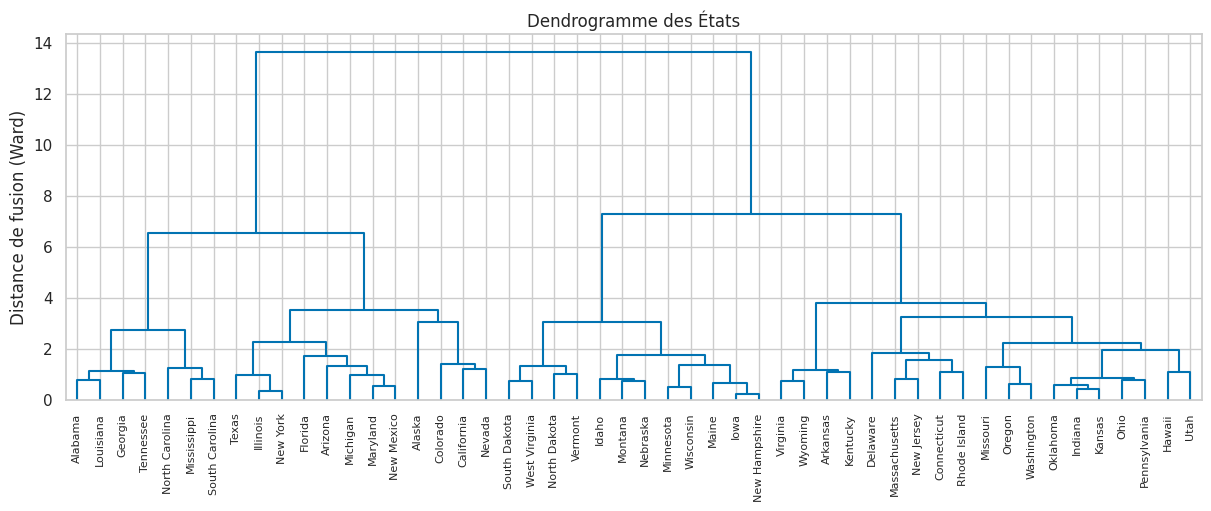

AMI entre Groupe k-means et Groupe CAH : 0.83


Groupe CAH,0,1,2,3
Groupe k-means,,,,
0,16,0,0,0
1,1,0,0,7
2,1,0,12,0
3,1,12,0,0


In [9]:
links = linkage(inputs_std, method="ward")

fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
dendrogram(links, labels=list(data.index), leaf_rotation=90, leaf_font_size=8, color_threshold=0, ax=ax)
ax.set(ylabel="Distance de fusion (Ward)", title="Dendrogramme des États")
plt.show()

data["Groupe CAH"] = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(inputs_std)
print(f"AMI entre Groupe k-means et Groupe CAH : {adjusted_mutual_info_score(data['Groupe k-means'], data['Groupe CAH']):.2f}")
pd.crosstab(data["Groupe k-means"], data["Groupe CAH"])

Les deux méthodes donnent presque les mêmes quatre groupes (AMI = 0.83), à trois États près.